# BIRCH — Clustering Large Datasets with Cluster Features

## 1. Definition and intuition
BIRCH (Balanced Iterative Reducing and Clustering using Hierarchies) incrementally summarizes data using a clustering-feature (CF) tree. A CF summary is $(N, LS, SS)$: number of points, linear sum, and squared-sum information. These summaries support mean and radius calculations without retaining every point in a microcluster.

BIRCH is designed to reduce a large dataset to a manageable set of subclusters and may then apply a global clustering method to those summaries.

## 2. Cluster-feature math
For a microcluster $C$,
$$
N=|C|,\quad LS=\sum_{x\in C}x,\quad SS=\sum_{x\in C}\|x\|^2.
$$
The centroid is $LS/N$ and the squared radius is $SS/N-\|LS/N\|^2$. CFs are additive: summaries of two groups can be merged by summing N, LS and SS.

## 3. Why it works and limitations
CF summaries preserve sufficient statistics for mean and squared-radius calculations under Euclidean geometry. The CF-tree organizes these compact summaries. But early compression can discard fine structure, input order can matter, and a single threshold may be unsuitable for multi-density data.

The educational implementation below demonstrates CF summaries and greedy microcluster compression; it is not a complete reproduction of BIRCH's balanced CF-tree node splitting.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.cluster import Birch, KMeans
from sklearn.metrics import adjusted_rand_score

SEED = 42
X, y = make_blobs(n_samples=6000, centers=5, n_features=2, cluster_std=0.65, random_state=SEED)


## 4. CF summaries from scratch

We insert a point into its nearest existing microcluster when the updated microcluster radius stays under a threshold; otherwise we create a new microcluster. This simplified method illustrates streaming summaries but omits BIRCH's multi-level balanced tree.

Input points: 1200 microclusters: 65
Compression ratio: 18.46


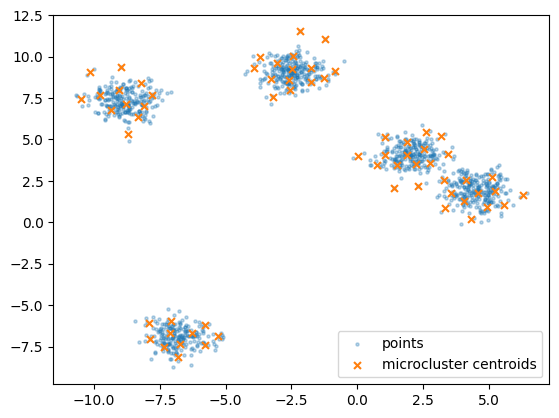

In [2]:
class CFMicrocluster:
    def __init__(self, x):
        self.n = 1
        self.ls = np.asarray(x, dtype=float).copy()
        self.ss = float(np.dot(x, x))

    @property
    def centroid(self):
        return self.ls / self.n

    @property
    def radius(self):
        return float(np.sqrt(max(self.ss/self.n - np.dot(self.centroid, self.centroid), 0.0)))

    def add(self, x):
        self.n += 1
        self.ls += x
        self.ss += float(np.dot(x, x))

def cf_stream_compress(X, threshold=0.45):
    X = np.asarray(X, dtype=float)
    if X.ndim != 2 or len(X) == 0 or not np.isfinite(X).all():
        raise ValueError("X must be a non-empty finite 2D array")
    if threshold <= 0:
        raise ValueError("threshold must be positive")
    clusters = []
    for x in X:
        if not clusters:
            clusters.append(CFMicrocluster(x)); continue
        distances = np.array([np.linalg.norm(c.centroid-x) for c in clusters])
        idx = int(np.argmin(distances))
        c = clusters[idx]
        combined_n = c.n + 1
        combined_ls = c.ls + x
        combined_ss = c.ss + float(x @ x)
        center = combined_ls / combined_n
        radius = np.sqrt(max(combined_ss/combined_n - center@center, 0.0))
        if radius <= threshold:
            c.add(x)
        else:
            clusters.append(CFMicrocluster(x))
    return clusters

microclusters = cf_stream_compress(X[:1200], threshold=0.42)
centers = np.stack([c.centroid for c in microclusters])
print("Input points:", 1200, "microclusters:", len(microclusters))
print("Compression ratio:", round(1200/len(microclusters), 2))
plt.scatter(X[:1200,0], X[:1200,1], s=5, alpha=.3, label="points")
plt.scatter(centers[:,0], centers[:,1], s=25, marker="x", label="microcluster centroids")
plt.legend(); plt.show()


## 5. Compare with scikit-learn BIRCH

Scikit-learn's BIRCH uses a CF-tree with branching-factor controls. Its final `n_clusters` stage can cluster leaf subcluster centroids.

In [3]:
birch = Birch(threshold=0.42, branching_factor=50, n_clusters=5).fit(X)
print("sklearn BIRCH ARI:", round(adjusted_rand_score(y, birch.labels_), 4))
km = KMeans(n_clusters=5, n_init=5, random_state=SEED).fit(X)
print("K-means ARI:", round(adjusted_rand_score(y, km.labels_), 4))


sklearn BIRCH ARI: 0.9856
K-means ARI: 0.9963


## 6. Hyperparameters and complexity

- `threshold`: radius bound that controls microcluster granularity; smaller values create more subclusters.
- `branching_factor`: maximum number of CF entries per tree node.
- `n_clusters`: optional global clustering stage applied to subcluster centers.
- The conceptual streaming pass is roughly linear in n times the number of microclusters searched; the educational nearest-microcluster implementation can be $O(nMd)$ with M microclusters. A real CF-tree uses hierarchy to speed the search.
- Memory is driven by CF-tree entries rather than all raw observations, but in worst cases many microclusters can remain.
- BIRCH can process data incrementally; fit partial batches when supported by the estimator workflow.
- The CF summaries are Euclidean and are not directly equivalent for arbitrary distance metrics.

## 7. GPU and synthesis
BIRCH's benefit is compact incremental summaries and tree-based search, not GPU matrix throughput. GPU acceleration is not the standard path for scikit-learn BIRCH. If microclusters are already small, CPU memory and search efficiency may dominate. Use BIRCH when the data volume is large and its Euclidean microcluster assumption is appropriate.

In [4]:
assert centers.ndim == 2 and centers.shape[1] == X.shape[1]
assert all(c.n >= 1 and c.radius >= 0 for c in microclusters)
try:
    cf_stream_compress(np.array([1,2,3]), 0.5)
except ValueError:
    pass
else:
    raise AssertionError("Expected invalid input shape to raise")
print("All BIRCH/CF summary checks passed.")


All BIRCH/CF summary checks passed.
